<a href="https://colab.research.google.com/github/SamAnguloUNT/Sam_INFO4670_Fall2026/blob/main/SJA0203_Assignment3_AssociationRuleMining_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3 — Association Rule Mining

**Dataset:** `bread_basket.csv` (11569 transactions)

Fill in the short answer cells and run the code cells. This notebook generates the required tables and figures.

**Sections:**
1. Setup & Data Load
2. EDA (a–e)
3. Frequent Itemset Mining (FP-Growth)
4. Association Rules + Report Table
5. Rule Subgraph (Bread, Coffee, Cake, Tea)
6. Interpretation Prompt


## 1) Setup & Data Load (10 pts)
- Place `bread_basket.csv` in the same folder as this notebook **or** update the path below.
- Needed packages: `pandas`, `matplotlib`, `mlxtend`, `networkx` (for the small graph).
- If a package is missing, run the `pip install` cell.

In [1]:
# Uncomment if needed
%pip install pandas mlxtend matplotlib networkx

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules
import networkx as nx
import warnings
warnings.filterwarnings("ignore")

# Load data – update path if necessary
CSV_PATH = "bread_basket.csv"
df = pd.read_csv(CSV_PATH)

# Standardize column names to match the lecture style (optional but convenient)
df.columns = [c.lower() for c in df.columns]   # → transaction, item, ...

print(df.shape)
df.head()

(20507, 6)


,transaction,item,date_time,time,period_day,weekday_weekend
0,1,Bread,30/10/2016,9:58,morning,weekend
1,2,Scandinavian,30/10/2016,10:05,morning,weekend
2,2,Scandinavian,30/10/2016,10:05,morning,weekend
3,3,Hot chocolate,30/10/2016,10:07,morning,weekend
4,3,Jam,30/10/2016,10:07,morning,weekend


## 2) EDA (a–e) (30 pts)
### a) List variables and their dtypes (5 pts)

In [2]:
# write your answer here
print(df.dtypes)
# or
df.info()


transaction         int64
item               object
date_time          object
time               object
period_day         object
weekday_weekend    object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   transaction      20507 non-null  int64 
 1   item             20507 non-null  object
 2   date_time        20507 non-null  object
 3   time             20507 non-null  object
 4   period_day       20507 non-null  object
 5   weekday_weekend  20507 non-null  object
dtypes: int64(1), object(5)
memory usage: 961.4+ KB


### b) "Statistics" overview (5 pts)
Use `describe(include='all')` as a stand‑in for Statistics.

In [3]:
df.describe(include="all")

,transaction,item,date_time,time,period_day,weekday_weekend
count,20507.000000,20507,20507,20507,20507,20507
unique,NaN,94,159,1255,4,2
top,NaN,Coffee,2017-02-04,11:06,afternoon,weekday
freq,NaN,5471,292,52,11569,12807
mean,4976.202370,NaN,NaN,NaN,NaN,NaN
std,2796.203001,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN
25%,2552.000000,NaN,NaN,NaN,NaN,NaN
50%,5137.000000,NaN,NaN,NaN,NaN,NaN
75%,7357.000000,NaN,NaN,NaN,NaN,NaN


### c) Bar plot — count of **unique transactions per item** (10 pts)
Set the subtitle to your **FirstName LastName**.

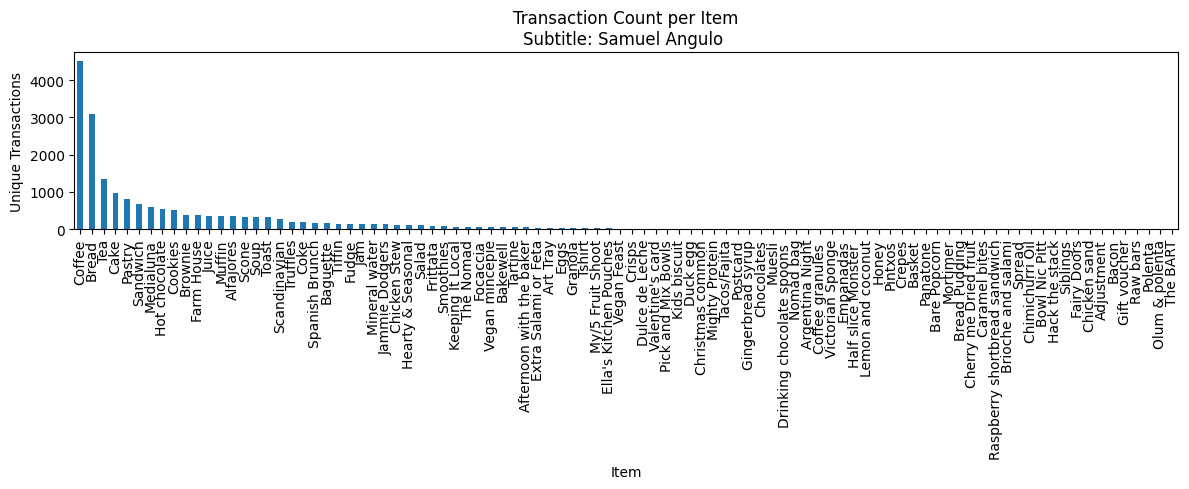

In [4]:
# c) Bar plot of transaction counts per item
subtitle = "Samuel Angulo "  # <-- EDIT THIS

item_counts = (df.groupby("item")["transaction"]
                 .nunique()
                 .sort_values(ascending=False))

ax = item_counts.plot(kind='bar', figsize=(12,5))
plt.title(f"Transaction Count per Item\nSubtitle: {subtitle}")
plt.xlabel("Item"); plt.ylabel("Unique Transactions")
plt.tight_layout()
plt.show()

### d) Report counts for Coffee, Tea, Alfajores, Juice, and Chicken Stew (10 pts)

In [5]:
# write your answer here
items = ["Coffee", "Tea", "Alfajores", "Juice", "Chicken Stew"]
counts = (df[df["item"].isin(items)]
          .groupby("item")["transaction"]
          .nunique()
          .reindex(items))
print(counts)

item
Coffee          4528
Tea             1350
Alfajores        344
Juice            365
Chicken Stew     123
Name: transaction, dtype: int64


## 3) Frequent Itemset Mining with FP‑Growth (min_support = 0.02) (20 pts)
We pivot the data to a **transaction × item** one‑hot table (boolean), then run FP‑Growth.

In [6]:
# write your answer here
basket_list = (df.groupby("transaction")["item"]
                 .apply(list)
                 .tolist())

te = TransactionEncoder()
oht = pd.DataFrame(te.fit(basket_list).transform(basket_list),
                   columns=te.columns_).astype(bool)

print("One-hot shape:", oht.shape)

freq = fpgrowth(oht, min_support=0.02, use_colnames=True)
freq = freq.sort_values("support", ascending=False)
print(freq)
print(f"\nNumber of frequent itemsets: {len(freq)}")

One-hot shape: (9465, 94)
     support                 itemsets
5   0.478394                 (Coffee)
0   0.327205                  (Bread)
8   0.142631                    (Tea)
12  0.103856                   (Cake)
19  0.090016          (Bread, Coffee)
6   0.086107                 (Pastry)
13  0.071844               (Sandwich)
7   0.061807              (Medialuna)
2   0.058320          (Hot chocolate)
28  0.054728           (Coffee, Cake)
3   0.054411                (Cookies)
25  0.049868            (Coffee, Tea)
22  0.047544         (Pastry, Coffee)
15  0.040042                (Brownie)
9   0.039197             (Farm House)
10  0.038563                  (Juice)
4   0.038457                 (Muffin)
31  0.038246       (Sandwich, Coffee)
14  0.036344              (Alfajores)
24  0.035182      (Medialuna, Coffee)
18  0.034548                  (Scone)
11  0.034443                   (Soup)
17  0.033597                  (Toast)
20  0.029583  (Coffee, Hot chocolate)
23  0.029160          (P

## 4) Association Rules + Report Table (30 pts)
(metric = confidence, min_threshold = ?) Please find a suitable min_threshold

In [7]:
# write your answer here
min_threshold = 0.5

rules = association_rules(freq, metric="confidence", min_threshold=min_threshold)

report = (rules[["antecedents", "consequents", "support", "confidence", "lift"]]
          .sort_values("confidence", ascending=False)
          .reset_index(drop=True))

report["antecedents"] = report["antecedents"].apply(lambda x: ", ".join(sorted(x)))
report["consequents"] = report["consequents"].apply(lambda x: ", ".join(sorted(x)))

print(report.to_string(index=False))
print(f"\nNumber of rules: {len(report)}")

  antecedents consequents  support  confidence     lift
        Toast      Coffee 0.023666    0.704403 1.472431
    Medialuna      Coffee 0.035182    0.569231 1.189878
       Pastry      Coffee 0.047544    0.552147 1.154168
        Juice      Coffee 0.020602    0.534247 1.116750
     Sandwich      Coffee 0.038246    0.532353 1.112792
         Cake      Coffee 0.054728    0.526958 1.101515
      Cookies      Coffee 0.028209    0.518447 1.083723
Hot chocolate      Coffee 0.029583    0.507246 1.060311

Number of rules: 8


## 5) Rule Subgraph

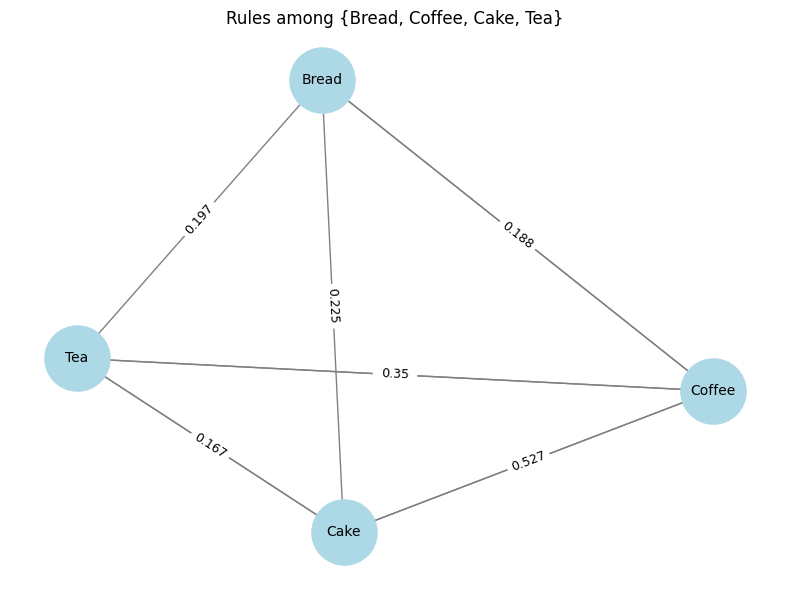

In [8]:
# write your answer here
focus = {"Bread", "Coffee", "Cake", "Tea"}

rules_low = association_rules(freq, metric="confidence", min_threshold=0.1)

sub = rules_low[
    rules_low["antecedents"].apply(lambda s: s.issubset(focus)) &
    rules_low["consequents"].apply(lambda s: s.issubset(focus))
].copy()

G = nx.DiGraph()
for _, r in sub.iterrows():
    a = ",".join(sorted(list(r["antecedents"])))
    c = ",".join(sorted(list(r["consequents"])))
    G.add_edge(a, c, weight=round(r["confidence"], 3))

plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42)
nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=2200)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=20, edge_color="gray")
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9)
plt.title("Rules among {Bread, Coffee, Cake, Tea}")
plt.axis("off")
plt.tight_layout()
plt.show()

## 6) Interpretation (10 pts)
**Interpret the rule `{Coffee, Cake} ⇒ {Bread}` in plain English.**

- **Support**: What fraction of *all* transactions contain Coffee, Cake, and Bread together?
- **Confidence**: Among baskets with Coffee and Cake, what share also include Bread?
- **Lift > 1** implies positive association; comment on practical meaning.

*Your notes:* (write your answer here)



Support: Based on our results only about 1% of all transactions contain coffee, cake, and bread together. So having all three items in one transaction does not happen often.

Confidence: So among baskets with coffee and cake, it shows that about 18% also include bread in the basket. This shows us that if someone has bought both coffee and cake that it's unlikely they will also buy bread, however 18% isn't incredibly unlikely.

Lift: The lift is less than 1 at about .56, this implies that it is a negative association. Although bread is in about 33% of baskets, the problem is that it is only in about 18% of coffee and cake baskets. Anyone who would purchase a coffee and cake basket is about 44% less likely to purchase bread as well. This wouldn't be a good association at all as it wouldn't happen often.

In [9]:
total = oht.shape[0]
supp_ccb = ((oht["Coffee"] & oht["Cake"] & oht["Bread"]).sum()) / total
supp_cc  = ((oht["Coffee"] & oht["Cake"]).sum()) / total
conf     = supp_ccb / supp_cc
lift     = conf / oht["Bread"].mean()

print(f"Support   : {supp_ccb:.4f}")
print(f"Confidence: {conf:.4f}")
print(f"Lift      : {lift:.4f}")

Support   : 0.0100
Confidence: 0.1834
Lift      : 0.5605
